# imports

In [1]:
import pandas as pd
import os
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# load data

## collect all the filenames that belong to good experimental days

In [2]:
# here are the extracted spike trains, one for each day-session-area combination
spike_directory = '/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/extracted_spike_trains/'

# animal-day-combinations where there's CNO and at least one pre- and post-session
good_combinations = ["model144_d16",
                    "model161_d10",
                    "model161_d12",
                    "model248_d11",
                    "model368_d14",
                    "model368_d16",
                    "model550_d16",
                    "model550_d17",
                    "model550_d21",
                    "model556_d12",
                    "model556_d13",
                    "model556_d19",
                    "model572_d16",
                    "model572_d17",
                    "model572_d18",
                    "model1216_d10",
                    "model1216_d12",
                    "model1223_d12",
                    "model1223_d13",
                    "model1223_d14",
                    "model1223_d15",
                    "model1232_d13",
                    "model1232_d14",
                    "model1232_d15",
                    # "model248_d04" # not really useable, since it's: sleep - cno_2 - lt1
                    ]

    # get all filenames in spike_directory that match good_combinations

spike_filenames = []
for f in os.listdir(spike_directory):
    for combo in good_combinations:
        if f.startswith(combo):
            spike_filenames.append(f)
            break
spike_filenames.sort()
print(spike_filenames)

['model1216_d10_cno?_tt1_CA2_post.npy', 'model1216_d10_cno?_tt2_CA3a_post.npy', 'model1216_d10_cno?_tt3_CA3c_post.npy', 'model1216_d10_cno?_tt4_CA1_post.npy', 'model1216_d10_cno?_tt5_CA2_post.npy', 'model1216_d10_cno?_tt6_CA1_post.npy', 'model1216_d10_cno?_tt7_CA3c_post.npy', 'model1216_d10_cno?_tt8_CA1_post.npy', 'model1216_d10_lt11_tt1_CA2_pre.npy', 'model1216_d10_lt11_tt2_CA3a_pre.npy', 'model1216_d10_lt11_tt3_CA3c_pre.npy', 'model1216_d10_lt11_tt4_CA1_pre.npy', 'model1216_d10_lt11_tt5_CA2_pre.npy', 'model1216_d10_lt11_tt6_CA1_pre.npy', 'model1216_d10_lt11_tt7_CA3c_pre.npy', 'model1216_d10_lt11_tt8_CA1_pre.npy', 'model1216_d10_lt12_tt1_CA2_post.npy', 'model1216_d10_lt12_tt2_CA3a_post.npy', 'model1216_d10_lt12_tt3_CA3c_post.npy', 'model1216_d10_lt12_tt4_CA1_post.npy', 'model1216_d10_lt12_tt5_CA2_post.npy', 'model1216_d10_lt12_tt6_CA1_post.npy', 'model1216_d10_lt12_tt7_CA3c_post.npy', 'model1216_d10_lt12_tt8_CA1_post.npy', 'model1216_d10_lt21_tt1_CA2_post.npy', 'model1216_d10_lt21_tt2

## put the information of the filenames into a nice dataframe

In [3]:
# example filename: 'model144_d10_cno2_tt7_CA2_post.npy'
# Initialize lists to store parsed data
animals = []
days = []
tasks = []
tetrodes = []
areas = []
treatments = []
filename_list = []
start_times = []
end_times = []
total_spikes = []
cno_injections = []
avg_activity_pre = []

# Parse each filename
for filename in spike_filenames:
    # Remove the '.npy'
    base = filename.split('.')[0]
    # Split by underscores
    parts = base.split('_')

    # Assign parts to variables
    animals.append(parts[0][5:]) # remove the 'model' from 'model144'
    days.append(parts[1][1:])  # Remove 'd' from 'd10'
    tasks.append(parts[2])
    tetrodes.append(parts[3][-1]) # get the '7' from tt7
    areas.append(parts[4])
    treatments.append(parts[5])
    filename_list.append(filename)
    
    # some will be populated later
    start_times.append(0) # first spike of a session
    end_times.append(0)
    total_spikes.append(0) # total spikes in a session. We'll then compute spiking density
    cno_injections.append(0)
    avg_activity_pre.append(0.0) # make sure that it's a float not an integer

# Create the DataFrame
df = pd.DataFrame({
    'Model': animals,
    'Day': days,
    'Session': tasks,
    'Tetrode': tetrodes,
    'Area': areas,
    'Treatment': treatments,
    'Start_time': start_times,
    'End_time': end_times,
    'Activity_total': total_spikes,
    'CNO_injection': cno_injections,
    'Avg_activity_pre': avg_activity_pre,
    'Filename': filename_list
})

# Display the DataFrame
# print(df)

## replace unclear area annotations or remove the data

In [4]:
print(df['Area'].unique())

df = df[~df['Area'].isin(['DEEP', 'CA2-CA1', 'CA3-CA2'])]
df['Area'] = df['Area'].replace({'CA3a': 'CA3', 'CA3b': 'CA3', 'CA3c': 'CA3', 'CA13b': 'CA3'})
print(df['Area'].unique())

['CA2' 'CA3a' 'CA3c' 'CA1' 'CA3b' 'CA13b' 'CA3' 'DEEP' 'CA2-CA1' 'CA3-CA2']
['CA2' 'CA3' 'CA1']


## find and add the start times

In [5]:
# 2 things
## 1: get start and end time from each spike train to compute the session borders
## 2: create a dict that stores all the loaded spike trains, making them more readily accessible

spike_train_dict = defaultdict(lambda: defaultdict(lambda: defaultdict(lambda: defaultdict(dict))))

for index, row in df.iterrows():
    spike_train = np.load(f'{spike_directory}/{row['Filename']}')
    df.loc[index, 'Start_time'] = spike_train[0] # unit is microsecond (1/1000th milisecond)
    df.loc[index, 'End_time'] = spike_train[-1]
    df.loc[index, 'Activity_total'] = len(spike_train)
    spike_train_dict[df.loc[index, 'Model']][df.loc[index, 'Day']][df.loc[index, 'Session']][df.loc[index, 'Area']][df.loc[index, 'Tetrode']] = spike_train

In [7]:
df

,Model,Day,Session,Tetrode,Area,Treatment,Start_time,End_time,Activity_total,CNO_injection,Avg_activity_pre,Filename
0,1216,10,cno?,1,CA2,post,11657595304,13454833545,628400,0,0.0,model1216_d10_cno?_tt1_CA2_post.npy
1,1216,10,cno?,2,CA3,post,11657607223,13454637613,37608,0,0.0,model1216_d10_cno?_tt2_CA3a_post.npy
2,1216,10,cno?,3,CA3,post,11657706541,13454337478,27242,0,0.0,model1216_d10_cno?_tt3_CA3c_post.npy
3,1216,10,cno?,4,CA1,post,11657605963,13454827094,201234,0,0.0,model1216_d10_cno?_tt4_CA1_post.npy
4,1216,10,cno?,5,CA2,post,11657598867,13454831548,254015,0,0.0,model1216_d10_cno?_tt5_CA2_post.npy
...,...,...,...,...,...,...,...,...,...,...,...,...
829,572,18,sleep2,7,CA2,post,7264278399,8694556102,18186,0,0.0,model572_d18_sleep2_tt7_CA2_post.npy
830,572,18,sleep2,8,CA2,post,7264275388,8694545627,45441,0,0.0,model572_d18_sleep2_tt8_CA2_post.npy
832,572,18,sleep3,3,CA1,post,9358214394,11298776672,85068,0,0.0,model572_d18_sleep3_tt3_CA1_post.npy
834,572,18,sleep3,7,CA2,post,9358235406,11298794336,24501,0,0.0,model572_d18_sleep3_tt7_CA2_post.npy


get the earliest and latest timestamp for each session (across tetrodes)

In [6]:
session_times = df.groupby(['Model', 'Day', 'Session']).agg(
    Start_time_min=('Start_time', 'min'),
    End_time_max=('End_time', 'max')
)
#print(session_times)

session_times = session_times.groupby(level=['Model', 'Day']).apply(lambda x: x.sort_values('Start_time_min'))
session_times = session_times.reset_index(level=[0, 1], drop=True)

In [7]:
# Get CNO start times for each model-day combination
# add the CNO-injection time to each session in df so we know when it is relative to injection
cno_starts = {}
for (model, day), group in session_times.groupby(level=['Model', 'Day']):
    cno_session = group[group.index.get_level_values('Session').str.startswith('cno')]
    df.loc[(df['Model'] == model) & (df['Day'] == day), 'CNO_injection'] = cno_session['Start_time_min'].iloc[0]


In [10]:
df

,Model,Day,Session,Tetrode,Area,Treatment,Start_time,End_time,Activity_total,CNO_injection,Avg_activity_pre,Filename
0,1216,10,cno?,1,CA2,post,11657595304,13454833545,628400,11657595304,0.0,model1216_d10_cno?_tt1_CA2_post.npy
1,1216,10,cno?,2,CA3,post,11657607223,13454637613,37608,11657595304,0.0,model1216_d10_cno?_tt2_CA3a_post.npy
2,1216,10,cno?,3,CA3,post,11657706541,13454337478,27242,11657595304,0.0,model1216_d10_cno?_tt3_CA3c_post.npy
3,1216,10,cno?,4,CA1,post,11657605963,13454827094,201234,11657595304,0.0,model1216_d10_cno?_tt4_CA1_post.npy
4,1216,10,cno?,5,CA2,post,11657598867,13454831548,254015,11657595304,0.0,model1216_d10_cno?_tt5_CA2_post.npy
...,...,...,...,...,...,...,...,...,...,...,...,...
829,572,18,sleep2,7,CA2,post,7264278399,8694556102,18186,3273498341,0.0,model572_d18_sleep2_tt7_CA2_post.npy
830,572,18,sleep2,8,CA2,post,7264275388,8694545627,45441,3273498341,0.0,model572_d18_sleep2_tt8_CA2_post.npy
832,572,18,sleep3,3,CA1,post,9358214394,11298776672,85068,3273498341,0.0,model572_d18_sleep3_tt3_CA1_post.npy
834,572,18,sleep3,7,CA2,post,9358235406,11298794336,24501,3273498341,0.0,model572_d18_sleep3_tt7_CA2_post.npy


# test visualization for one session

In [11]:
selection = df[(df['Model'] == '1216') & (df['Day'] == '12')]
first_index = selection.index[0]
inject_time = selection.loc[first_index, 'CNO_injection'] # take any row out of that day
sel_train = spike_train_dict['1216']['12']['lt12']['CA2']['1'].copy()
sel_train = sel_train - inject_time
sel_train = sel_train / 60000000 # microseconds to minutes
subsampled = sel_train[::50]

## spike raster plot

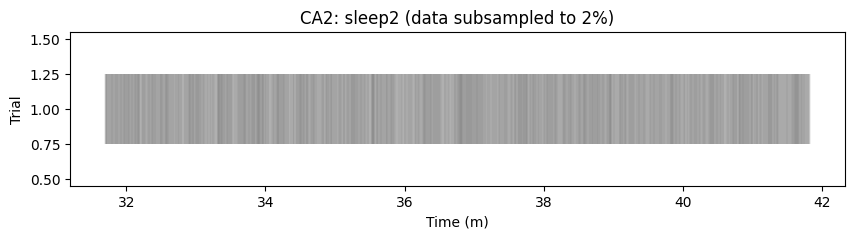

In [12]:
# Create a spike raster plot
plt.figure(figsize=(10, 2))
plt.eventplot(subsampled, lineoffsets=1, linelengths=0.5, colors='k', alpha = 0.03)
plt.xlabel('Time (m)')
plt.ylabel('Trial')
plt.title('CA2: sleep2 (data subsampled to 2%)')
plt.show()

# calculate shutdown window

In [8]:
# compute session length and rate of firing
duration = df['End_time'] - df['Start_time']     # will be used in the next cell as well
df['Duration'] = duration
df['avg_activity'] = df['Activity_total'] / duration * 60_000_000 # spikes per minute

# Activity relative to sleep 1

In [9]:
bin_size = 5 # in minutes. So now we bin activity to bin minutes


#------------
relative_ca2_dict = defaultdict(lambda: defaultdict(dict))

for model in spike_train_dict.keys():
    for day in spike_train_dict[model].keys():

        selection = df[(df['Model'] == model) & (df['Day'] == day)]
        # take any row out of that day to get CNO injection time
        first_index = selection.index[0]
        inject_time = selection.loc[first_index, 'CNO_injection'] 
        
        # get the cno session
        available_sessions = list(spike_train_dict[model][day].keys())
        cno_session = next((s for s in available_sessions if s.startswith('cno')), None)
        #cno_session = 'sleep1'###################################
        
        for tetrode in spike_train_dict[model][day][cno_session]['CA2'].keys():
            sel_train = spike_train_dict[model][day][cno_session]['CA2'][tetrode].copy() 
            #inject_time = sel_train[0]#######################################
            sel_train = sel_train - inject_time # relative to cno
            sel_train = sel_train / (60_000_000) # microseconds to minutes

            activity_pre = df[(df['Model'] == model) & (df['Day'] == day) & (df['Tetrode'] == tetrode) & (df['Session'] == 'sleep1')]['avg_activity']

            max_bin = int(np.ceil(sel_train[-1]))
            bins = np.arange(0, max_bin, bin_size)  # edges: 0,1,2,...
            counts, edges = np.histogram(sel_train, bins=bins)
            relative_binned_activity = counts / (activity_pre.values * bin_size)
            
            relative_ca2_dict[model][day][tetrode] = relative_binned_activity


## visualize average activity decay

### all trends in one plot

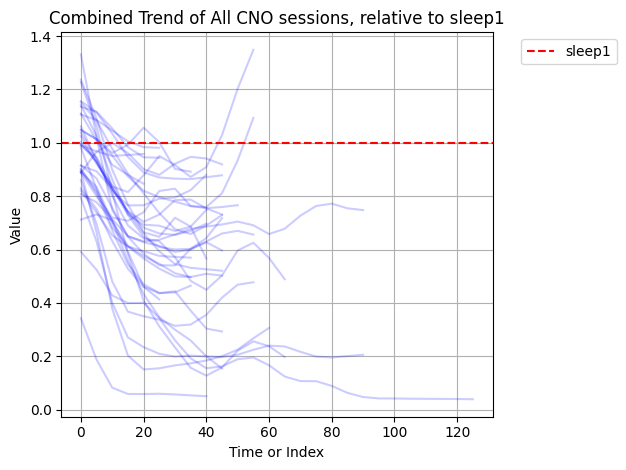

In [ ]:
smoothed = True
bin_size = 5 # in minutes

#----------------
for model in relative_ca2_dict.keys():
    for day in relative_ca2_dict[model].keys():
        for tetrode in relative_ca2_dict[model][day].keys():
            train = relative_ca2_dict[model][day][tetrode] # remove the last element because it's distorted
            x_axis = np.arange(len(train))*bin_size
            if smoothed:
                train = gaussian_filter1d(train, sigma=1)
            plt.plot(x_axis, train, alpha=0.2, color='blue')#, label=f'{model}_{day}_{tetrode}')


# Add labels and legend
plt.xlabel('Time or Index')
plt.ylabel('Value')
plt.title('Combined Trend of All CNO sessions, relative to sleep1')
plt.grid(True)
plt.axhline(y=1, color='red', linestyle='--', label='sleep1')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # Place legend outside
# Show the plot
plt.tight_layout()
plt.show()

In [34]:
relative_ca2_dict[model][day][tetrode]

array([1.21365839, 1.05352376, 0.82922476, 0.69868556, 0.63421418,
       0.58159325, 0.61143429, 0.59651377, 0.55912037, 0.80226958])

In [35]:
gaussian_filter1d(arr, sigma=1)

array([1.14137602, 1.02553405, 0.86274628, 0.7294591 , 0.64813932,
       0.60976478,        nan,        nan,        nan,        nan,
              nan,        nan,        nan,        nan,        nan,
              nan,        nan,        nan,        nan,        nan,
              nan,        nan,        nan,        nan,        nan,
              nan])

### all trends averaged

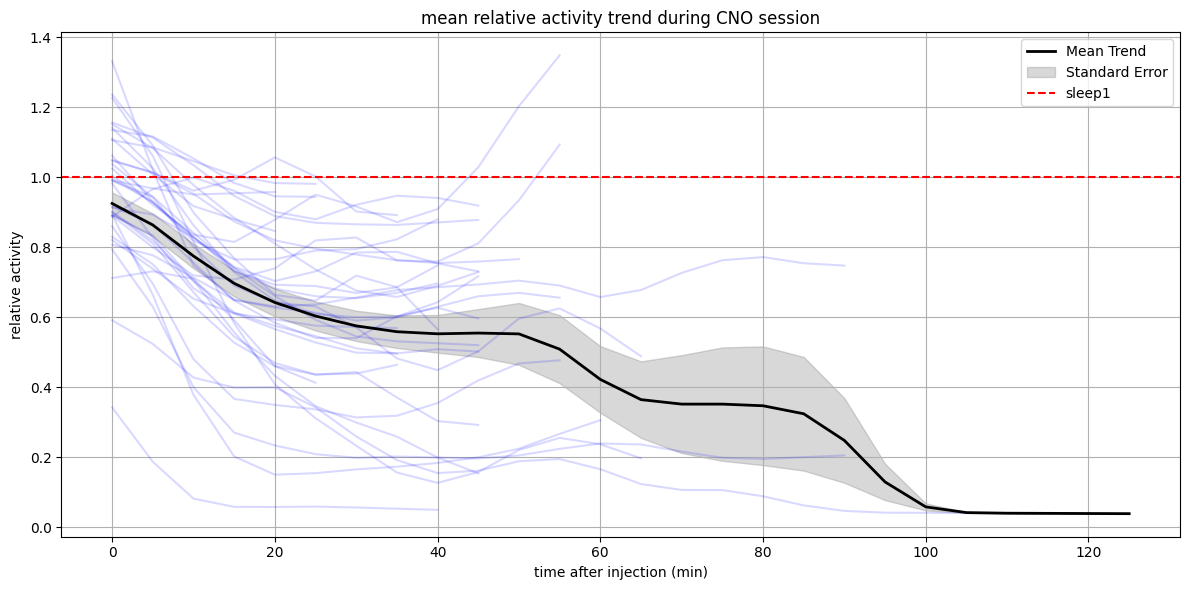

In [10]:
bin_size = 5
smooth = True

#---------
# Collect all arrays and determine the maximum length
arrays = []
for model in relative_ca2_dict.keys():
    for day in relative_ca2_dict[model].keys():
        for tetrode in relative_ca2_dict[model][day].keys():
            arrays.append(relative_ca2_dict[model][day][tetrode])
            
max_len = max(arr.shape[0] for arr in arrays)

# Pad shorter arrays with NaN to match max_len
padded_arrays = []
for arr in arrays:
    if smooth:
        arr = gaussian_filter1d(arr, sigma=1) # found out that you need to smoothen before padding
    padded_arr = np.pad(arr, (0, max_len - arr.shape[0]), mode='constant', constant_values=np.nan)
    padded_arrays.append(padded_arr)

# Stack padded arrays
stacked_arrays = np.vstack(padded_arrays)

# Compute mean and standard error for each timepoint
mean_trend = np.nanmean(stacked_arrays, axis=0)
std_error = np.nanstd(stacked_arrays, axis=0) / np.sqrt(np.sum(~np.isnan(stacked_arrays), axis=0))
std_error = gaussian_filter1d(std_error, sigma=1)


# Smooth the mean trend
smoothed_mean = gaussian_filter1d(mean_trend, sigma=1)

# Plot all arrays (optional, for reference)
plt.figure(figsize=(12, 6))
for arr in padded_arrays:
    x_axis = np.arange(len(arr))*bin_size
    plt.plot(x_axis, arr, color='blue', alpha=0.15)

# Plot the mean trend
x_axis = np.arange(len(smoothed_mean))*bin_size
plt.plot(x_axis, smoothed_mean, color='black', linewidth=2, label='Mean Trend')

# Shade the standard error
plt.fill_between(np.arange(max_len)*bin_size,
                 smoothed_mean - std_error,
                 smoothed_mean + std_error,
                 color='gray', alpha=0.3, label='Standard Error')

# Add a horizontal red line at y = 1
plt.axhline(y=1, color='red', linestyle='--', label='sleep1')

# Add labels and title
plt.xlabel('time after injection (min)')
plt.ylabel('relative activity')
plt.title('mean relative activity trend during CNO session')
plt.legend()
plt.grid(True)

# Show the plot
plt.tight_layout()
plt.show()

### all trends averaged with cutoff

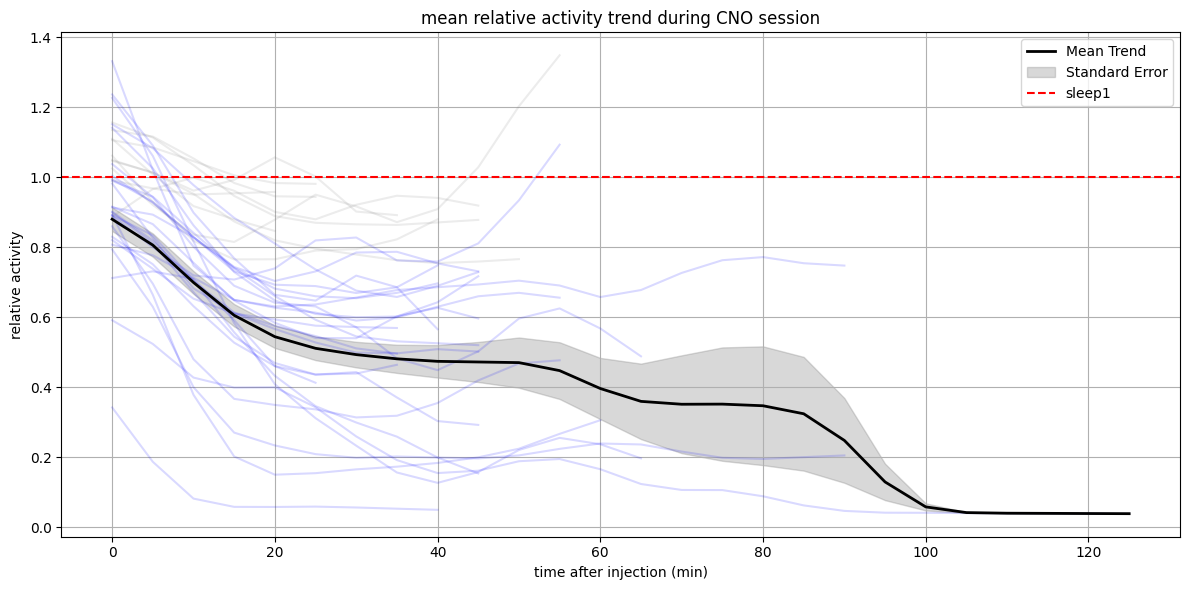

In [17]:
bin_size = 5
smooth = True
cutoff = 0.75 # all trials will be shown. But stats only calculated for trials with at least one value under cutoff

#---------
# Collect all arrays and determine the maximum length
arrays = []
for model in relative_ca2_dict.keys():
    for day in relative_ca2_dict[model].keys():
        for tetrode in relative_ca2_dict[model][day].keys():
            arrays.append(relative_ca2_dict[model][day][tetrode])
            
max_len = max(arr.shape[0] for arr in arrays)

# Pad shorter arrays with NaN to match max_len
padded_arrays = []
padded_arrays_under_cutoff = []
for arr in arrays:
    if smooth:
        arr = gaussian_filter1d(arr, sigma=1) # found out that you need to smoothen before padding
    padded_arr = np.pad(arr, (0, max_len - arr.shape[0]), mode='constant', constant_values=np.nan)
    padded_arrays.append(padded_arr)
    
    if min(padded_arr) < cutoff:
        padded_arrays_under_cutoff.append(padded_arr)


# Stack padded arrays
stacked_arrays_u_cutoff = np.vstack(padded_arrays_under_cutoff)

# Compute mean and standard error for each timepoint
mean_trend = np.nanmean(stacked_arrays_u_cutoff, axis=0)
std_error = np.nanstd(stacked_arrays_u_cutoff, axis=0) / np.sqrt(np.sum(~np.isnan(stacked_arrays), axis=0))
std_error = gaussian_filter1d(std_error, sigma=1)


# Smooth the mean trend
smoothed_mean = gaussian_filter1d(mean_trend, sigma=1)

# Plot all arrays (optional, for reference)
plt.figure(figsize=(12, 6))
for arr in padded_arrays:
    x_axis = np.arange(len(arr))*bin_size
    if min(arr) < cutoff:
        plt.plot(x_axis, arr, color='blue', alpha=0.15)
    else:
        plt.plot(x_axis, arr, color='gray', alpha=0.15)

# Plot the mean trend
x_axis = np.arange(len(smoothed_mean))*bin_size
plt.plot(x_axis, smoothed_mean, color='black', linewidth=2, label='Mean Trend')

# Shade the standard error
plt.fill_between(np.arange(max_len)*bin_size,
                 smoothed_mean - std_error,
                 smoothed_mean + std_error,
                 color='gray', alpha=0.3, label='Standard Error')

# Add a horizontal red line at y = 1
plt.axhline(y=1, color='red', linestyle='--', label='sleep1')

# Add labels and title
plt.xlabel('time after injection (min)')
plt.ylabel('relative activity')
plt.title('mean relative activity trend during CNO session')
plt.legend()
plt.grid(True)

# Show the plot
plt.tight_layout()
plt.show()

### all trends averaged with cutoff, showing only data under cutoff

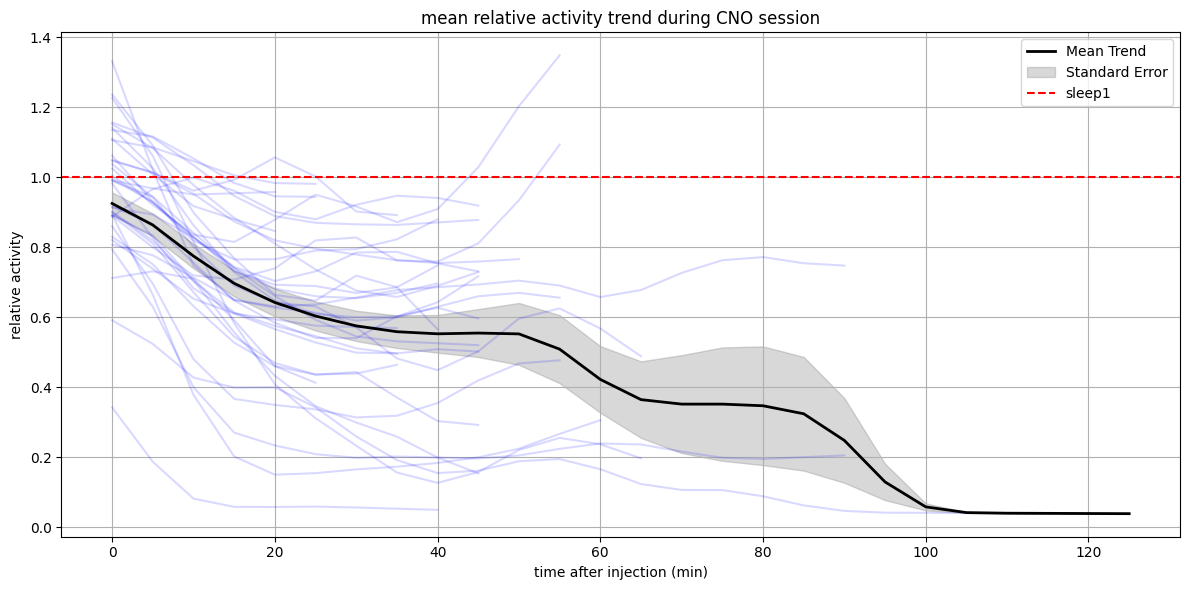

In [18]:
bin_size = 5
smooth = True
cutoff = .75

#---------
# Collect all arrays and determine the maximum length
arrays = []
for model in relative_ca2_dict.keys():
    for day in relative_ca2_dict[model].keys():
        for tetrode in relative_ca2_dict[model][day].keys():
            arrays.append(relative_ca2_dict[model][day][tetrode])
            
max_len = max(arr.shape[0] for arr in arrays)

# Pad shorter arrays with NaN to match max_len
padded_arrays = []
for arr in arrays:
    if smooth:
        arr = gaussian_filter1d(arr, sigma=1) # found out that you need to smoothen before padding
    padded_arr = np.pad(arr, (0, max_len - arr.shape[0]), mode='constant', constant_values=np.nan)
    padded_arrays.append(padded_arr)

# Stack padded arrays
stacked_arrays = np.vstack(padded_arrays)

# Compute mean and standard error for each timepoint
mean_trend = np.nanmean(stacked_arrays, axis=0)
std_error = np.nanstd(stacked_arrays, axis=0) / np.sqrt(np.sum(~np.isnan(stacked_arrays), axis=0))
std_error = gaussian_filter1d(std_error, sigma=1)


# Smooth the mean trend
smoothed_mean = gaussian_filter1d(mean_trend, sigma=1)

# Plot all arrays (optional, for reference)
plt.figure(figsize=(12, 6))
for arr in padded_arrays:
    arr[arr >= cutoff] = np.nan
    x_axis = np.arange(len(arr))*bin_size
    plt.plot(x_axis, arr, color='blue', alpha=0.15)

# Plot the mean trend
x_axis = np.arange(len(smoothed_mean))*bin_size
plt.plot(x_axis, smoothed_mean, color='black', linewidth=2, label='Mean Trend')

# Shade the standard error
plt.fill_between(np.arange(max_len)*bin_size,
                 smoothed_mean - std_error,
                 smoothed_mean + std_error,
                 color='gray', alpha=0.3, label='Standard Error')

# Add a horizontal red line at y = 1
plt.axhline(y=1, color='red', linestyle='--', label='sleep1')

# Add labels and title
plt.xlabel('time after injection (min)')
plt.ylabel('relative activity')
plt.title('mean relative activity trend during CNO session')
plt.legend()
plt.grid(True)

# Show the plot
plt.tight_layout()
plt.show()